# Track 1, Paso 3: anotación del VCF de variantes raras (snpEff + MyVariant.info + AlphaGenome)

**Entrada:** `data/track1_step2_rare_variants.vcf.gz` — las **591.339** variantes que sobreviven al Paso 2 (QC intrínseco + sustracción de dbSNP Common).
**Salida:** dos VCF en la raíz del repo, ambos gitignoreados porque contienen coordenadas del paciente:

| Archivo | Qué agrega | Script |
|---|---|---|
| `snpeff_annotated.vcf` | `ANN=` de snpEff (gen, consecuencia, impacto) para las 591.339 | `java -jar snpEff/snpEff.jar -canon GRCh38.99 …` |
| `track1_step3a_snpeff_filter.vcf.gz` | Solo HIGH/MODERATE + `GENE_SYMBOL`, `CONSEQUENCE`, `PUTATIVE_IMPACT`, `GNOMAD_AF`, `GNOMAD_EXOME_AF`, `CADD_PHRED`, `REVEL`, `CLINVAR_SIG`, `CLINVAR_REVIEW_STATUS`, `OMIM_PHENOTYPE` | `notebooks/notebook/track1_step3a_annotate.py` |
| `track1_step3b_regulatory_annotated.vcf.gz` | Lo anterior + `AVI_SCORE`, `AVI_QUANTILE`, `AVI_PHRED`, `REGULATORY_FEATURE`, `AVI_STATUS` | `notebooks/notebook/step3b_alphagenome.py` |

Este notebook **no vuelve a llamar a ninguna API**: lee esos archivos ya generados y resume qué quedó. Sirve para entender el resultado del paso y para detectar si algo se rompió al re-correrlo.

## Cómo reproducir (macOS, desde la raíz del repo)

```bash
source .venv/bin/activate
export PATH="/opt/homebrew/opt/openjdk@17/bin:$PATH"

# 3A.1  snpEff con transcrito canónico (-canon): una fila por variante, la consecuencia más severa
java -Xmx8g -jar snpEff/snpEff.jar -canon -noStats GRCh38.99 data/track1_step2_rare_variants.vcf.gz > snpeff_annotated.vcf

# 3A.2  Filtra HIGH/MODERATE y pide metadatos a MyVariant.info (hg38)
python notebooks/notebook/track1_step3a_annotate.py --workers 4

# 3B    Puntuación AVI de AlphaGenome Atlas (necesita ALPHAGENOME_API_KEY en ~/.env)
python notebooks/notebook/step3b_alphagenome.py
```

La base `GRCh38.99` de snpEff **no se puede descargar** (ver `CLAUDE.md`, sección snpEff): se construye una vez, localmente, desde Ensembl 99.

> Ver `docs/01-procedure.md` (Step 3) para la justificación de cada decisión y `docs/02-findings.md` para los hallazgos. Los números de este notebook corresponden a la corrida del 2026-09-17 en Apple Silicon.

In [1]:
import gzip, re
from collections import Counter
from pathlib import Path

import pandas as pd

# El notebook se ejecuta con notebooks/notebook/ como cwd (convención del repo: rutas relativas a la raíz vía ../..)
REPO = Path.cwd()
while not (REPO / "docs" / "01-procedure.md").exists():
    REPO = REPO.parent

STEP2   = REPO / "data" / "track1_step2_rare_variants.vcf.gz"
SNPEFF  = REPO / "snpeff_annotated.vcf"
STEP3A  = REPO / "track1_step3a_snpeff_filter.vcf.gz"
STEP3B  = REPO / "track1_step3b_regulatory_annotated.vcf.gz"

for p in (STEP2, SNPEFF, STEP3A, STEP3B):
    print(f"{'OK ' if p.exists() else 'FALTA'} {p.relative_to(REPO)}"
          + (f"  ({p.stat().st_size/1e6:.1f} MB)" if p.exists() else ""))

OK  data/track1_step2_rare_variants.vcf.gz  (27.3 MB)
OK  snpeff_annotated.vcf  (247.2 MB)
OK  track1_step3a_snpeff_filter.vcf.gz  (0.2 MB)
OK  track1_step3b_regulatory_annotated.vcf.gz  (0.2 MB)


## Utilidades de lectura

Los VCF de salida son texto (gzip normal, no bgzip), así que se leen con `gzip` y se parte cada línea por tabulador. El campo `INFO` (columna 8) es `clave=valor;clave=valor;…`; lo convertimos en un diccionario por variante. Nunca cargamos las 591k variantes del snpEff en memoria como DataFrame: solo contamos lo que hace falta mientras se leen.

In [2]:
def iter_vcf(path):
    # Devuelve (chrom, pos, ref, alt, info_dict, sample_fields) por variante, saltando el header.
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            p = line.rstrip("\n").split("\t")
            info = {}
            for kv in p[7].split(";"):
                k, sep, v = kv.partition("=")
                info[k] = v if sep else True
            yield p[0], int(p[1]), p[3], p[4], info, p[9:]

def first_ann(info):
    # snpEff escribe ANN=alt|consecuencia|impacto|gen|…; con -canon la primera entrada es la del transcrito canónico.
    ann = info.get("ANN")
    if not ann:
        return None
    return ann.split(",", 1)[0].split("|")

def zygosity(sample):
    gt = sample[0].split(":")[0].replace("|", "/")
    a = gt.split("/")
    if "." in a: return "UNKNOWN"
    if set(a) == {"0"}: return "HOM_REF"
    return "HOM_ALT" if len(set(a)) == 1 else "HET"

def fnum(x):
    try: return float(x)
    except (TypeError, ValueError): return None

## 3A.1 — snpEff: ¿qué impacto tienen las 591.339 variantes raras?

snpEff asigna a cada variante una **consecuencia** (missense, stop_gained, intron_variant, …) y un **impacto** en cuatro niveles:

| Impacto | Qué significa | Ejemplos |
|---|---|---|
| `HIGH` | Casi seguro rompe la proteína | stop_gained, frameshift, splice_donor/acceptor |
| `MODERATE` | Cambia la proteína, efecto incierto | missense, inframe_insertion/deletion |
| `LOW` | Probablemente inocuo | synonymous_variant |
| `MODIFIER` | Fuera de la región codificante | intron_variant, intergenic, UTR |

El flag `-canon` obliga a usar un solo transcrito (el canónico) por gen, así cada variante tiene **una** anotación en vez de una por isoforma. Sin él la salida se multiplica y el conteo de impactos se infla.

Según `docs/00-references.md` §3, ~85 % de las variantes patogénicas mendelianas conocidas están en exones o sitios de splicing, por lo que el pipeline se queda con `HIGH` + `MODERATE`.

In [3]:
impact_counts, consequence_counts = Counter(), Counter()
total = 0
for chrom, pos, ref, alt, info, _ in iter_vcf(SNPEFF):
    total += 1
    ann = first_ann(info)
    if ann is None:
        impact_counts["(sin ANN)"] += 1
        continue
    impact_counts[ann[2]] += 1
    if ann[2] in ("HIGH", "MODERATE"):
        consequence_counts[ann[1]] += 1

print(f"Variantes anotadas por snpEff: {total:,}")
impact_df = (pd.Series(impact_counts, name="variantes").rename_axis("impacto")
             .reindex(["HIGH", "MODERATE", "LOW", "MODIFIER", "(sin ANN)"]).dropna().astype(int).to_frame())
impact_df["%"] = (impact_df["variantes"] / total * 100).round(2)
impact_df

Variantes anotadas por snpEff: 591,339


,variantes,%
impacto,,
HIGH,202,0.03
MODERATE,1324,0.22
LOW,1316,0.22
MODIFIER,588497,99.52


Lectura: prácticamente todo lo que sobrevive al Paso 2 es `MODIFIER` (intrónico/intergénico). Las candidatas protein-altering son unas **1.500**, no las 10-20k que estimaba la procedure. Eso hace que los pasos 4 y 5 trabajen sobre un conjunto pequeño y que cada anotación adicional (gnomAD, CADD, ClinVar, AVI) pese mucho.

Consecuencias dentro de HIGH/MODERATE:

In [4]:
pd.Series(consequence_counts, name="variantes").sort_values(ascending=False).to_frame()

,variantes
missense_variant,1162
frameshift_variant,115
disruptive_inframe_deletion,67
disruptive_inframe_insertion,28
conservative_inframe_insertion,25
missense_variant&splice_region_variant,23
stop_gained,20
conservative_inframe_deletion,19
splice_acceptor_variant&intron_variant,16
splice_donor_variant&intron_variant,13


## 3A.2 — MyVariant.info: frecuencia poblacional, patogenicidad in-silico y ClinVar

`track1_step3a_annotate.py` toma las HIGH/MODERATE y pide a MyVariant.info, en lotes de 1.000 ids HGVS (`chr11:g.5227002T>A`, el rs334 de HBB como ejemplo), los campos:

| Tag INFO | Campo MyVariant | Para qué |
|---|---|---|
| `GNOMAD_AF` / `GNOMAD_EXOME_AF` | `gnomad_genome.af.af` / `gnomad_exome.af.af` | Frecuencia en población general: una variante causal de enfermedad ultra-rara no puede ser común |
| `CADD_PHRED` | `dbnsfp.cadd.phred` | Score de deleteriedad (≥20 = top 1 % del genoma) |
| `REVEL` | `dbnsfp.revel.score` | Patogenicidad de missense (≥0,5 sugiere patogénica) |
| `CLINVAR_SIG`, `CLINVAR_REVIEW_STATUS` | `clinvar.rcv.*` | Clasificación clínica ya reportada |
| `OMIM_PHENOTYPE` | `clinvar.rcv.conditions.identifiers.omim` | Enfermedad OMIM asociada al reporte ClinVar |

**Dos detalles que costaron una corrida entera:**

1. **`assembly=hg38` es obligatorio.** MyVariant busca en hg19 por defecto. Con coordenadas GRCh38 sin ese parámetro, 1.492 de 1.526 variantes salieron "notfound" y las 34 "encontradas" eran *otras* variantes que comparten coordenada en hg19. Cualquier salida anterior a esta corrección es inválida.
2. **Los indels necesitan HGVS válido.** `g.100AT>A` no es HGVS; hay que escribir `g.101del`, `g.100_101insCCT`, `g.101_102delinsCC`. El script ahora lo hace.

También cambió qué campos se piden: `cadd.phred` solo existe en hg19 (en hg38 llega vía dbNSFP) y `LoFtool` no existe en MyVariant, así que `LOFTOOL_SCORE` ya no se emite.

### Cobertura de la anotación

In [5]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3A):
    rows.append({
        "gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"), "consequence": info.get("CONSEQUENCE"),
        "type": "SNV" if len(ref) == 1 and len(alt.split(",")[0]) == 1 else "indel",
        "zygosity": zygosity(sample),
        "hit": "MYVARIANT_HIT" in info,
        "gnomad_af": fnum(info.get("GNOMAD_AF")), "gnomad_exome_af": fnum(info.get("GNOMAD_EXOME_AF")),
        "cadd": fnum(info.get("CADD_PHRED")), "revel": fnum(info.get("REVEL")),
        "clinvar": info.get("CLINVAR_SIG"), "omim": info.get("OMIM_PHENOTYPE"),
    })
a3 = pd.DataFrame(rows)
print(f"Variantes HIGH/MODERATE en la salida del 3A: {len(a3):,}  "
      f"(SNV {int((a3.type=='SNV').sum()):,}, indel {int((a3.type=='indel').sum()):,})")

coverage = pd.DataFrame({
    "con valor": [a3.hit.sum(), a3.gnomad_af.notna().sum(), a3.gnomad_exome_af.notna().sum(),
                  a3.cadd.notna().sum(), a3.revel.notna().sum(), a3.clinvar.notna().sum(), a3.omim.notna().sum()],
}, index=["MYVARIANT_HIT", "GNOMAD_AF", "GNOMAD_EXOME_AF", "CADD_PHRED", "REVEL", "CLINVAR_SIG", "OMIM_PHENOTYPE"])
coverage["% de 1.526"] = (coverage["con valor"] / len(a3) * 100).round(1)
coverage

Variantes HIGH/MODERATE en la salida del 3A: 1,526  (SNV 1,220, indel 306)


,con valor,% de 1.526
MYVARIANT_HIT,1526,100.0
GNOMAD_AF,1481,97.1
GNOMAD_EXOME_AF,1156,75.8
CADD_PHRED,1110,72.7
REVEL,864,56.6
CLINVAR_SIG,312,20.4
OMIM_PHENOTYPE,112,7.3


REVEL solo existe para missense (por eso ~860 y no 1.526) y ClinVar solo para variantes que alguien reportó: esos huecos son esperables, no fallas.

### El hallazgo importante: dbSNP Common no alcanza como filtro de frecuencia

El Paso 2 resta las variantes de `common_all_20180418.vcf.gz` (dbSNP b151, 2018). Miremos qué frecuencia tienen en gnomAD las que **pasaron** ese filtro:

In [6]:
def af_bin(af):
    if af is None: return "sin dato gnomAD"
    if af > 0.05:  return "> 5 %  (común)"
    if af > 0.01:  return "1-5 %  (común)"
    if af > 0.001: return "0,1-1 %"
    return "< 0,1 % (rara)"

a3["af_bin"] = a3.gnomad_af.map(af_bin)
order = ["> 5 %  (común)", "1-5 %  (común)", "0,1-1 %", "< 0,1 % (rara)", "sin dato gnomAD"]
tab = pd.crosstab(a3.af_bin, a3.type).reindex(order).fillna(0).astype(int)
tab["total"] = tab.sum(axis=1)
common = int((a3.gnomad_af > 0.01).sum())
print(f"{common:,} de {len(a3):,} variantes 'raras' tienen gnomAD AF > 1 %  ({common/len(a3)*100:.0f} %)")
tab

1,212 de 1,526 variantes 'raras' tienen gnomAD AF > 1 %  (79 %)


type,SNV,indel,total
af_bin,,,
> 5 % (común),906,257,1163
1-5 % (común),29,20,49
"0,1-1 %",84,11,95
"< 0,1 % (rara)",201,18,219
sin dato gnomAD,0,0,0


Matplotlib is building the font cache; this may take a moment.


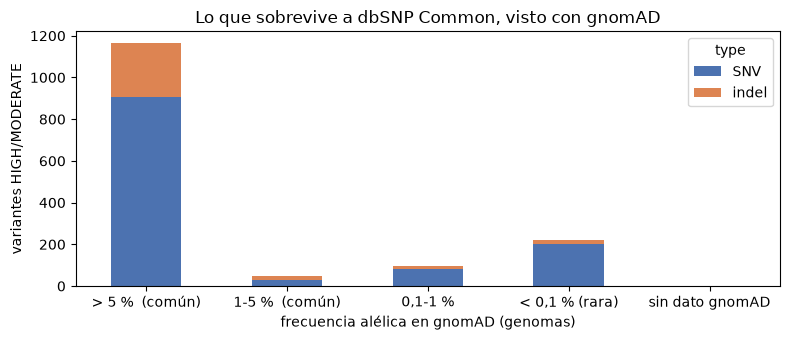

In [7]:
import matplotlib.pyplot as plt

ax = tab.drop(columns="total").plot.bar(stacked=True, figsize=(8, 3.5), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("variantes HIGH/MODERATE")
ax.set_xlabel("frecuencia alélica en gnomAD (genomas)")
ax.set_title("Lo que sobrevive a dbSNP Common, visto con gnomAD")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Verificamos con `tabix` una muestra de 300 de esas SNVs comunes contra el dbSNP local: **ninguna estaba en el archivo**. No es un bug de claves en `run_step2_prefilter.py`; la lista negra de 2018 simplemente no contiene la mayoría de las variantes codificantes que gnomAD marca como comunes (incluidos casos donde el genoma de referencia lleva el alelo minoritario, AF ≈ 0,9999). En indels es peor porque dbSNP los normaliza distinto (278 de 307 son comunes).

**Consecuencia para el equipo:** el filtro de frecuencia efectivo es `GNOMAD_AF` del Paso 3A. El Paso 5 descarta AF > 1 % (`--max-af 0.01`, el mismo umbral que justifica la procedure; no se baja más por la caución de efecto fundador de `00-references.md` §4). La solución estructural sería reemplazar dbSNP Common por una lista negra de gnomAD en el Paso 2.

### ClinVar: qué dice de lo que ya está reportado

In [8]:
clin = a3.clinvar.dropna().str.split("|").explode().str.replace("_", " ").value_counts().to_frame("variantes")
clin

,variantes
clinvar,
Benign,182
Uncertain significance,96
Likely benign,65
Benign/Likely benign,17
Conflicting interpretations of pathogenicity,9
Pathogenic,8
Likely pathogenic,5
not provided,4
drug response,3


## 3B — AlphaGenome Atlas: puntuación AVI

`step3b_alphagenome.py` pide al Atlas de AlphaGenome dos *scorers* para cada variante:

* **`AVI_SCORE`**: AlphaGenome Variant Impact, un score unificado de impacto molecular. Viene con un cuantil calibrado frente a todos los SNV del genoma; lo convertimos a **`AVI_PHRED` = −10·log10(1 − cuantil)**, la misma escala que CADD: ≥20 es el 1 % superior del genoma, ≥30 el 0,1 %.
* **`AVI_SCORE_FEATURE_IMPORTANCE`**: 18 modalidades (splicing, AlphaMissense, conservación Cactus/phastCons, RNA-seq, DNase, …). Guardamos la de mayor atribución en **`REGULATORY_FEATURE`**: dice *por qué* el modelo cree que la variante importa.

Limitaciones descubiertas contra la API real (alphagenome 0.9.0):

* **Solo SNV.** Todo indel devuelve `NotImplementedError`; el script los marca `AVI_STATUS=indel_unsupported` sin gastar una llamada.
* El servidor valida el alelo REF contra GRCh38 y un solo error tumba el lote; el script reintenta variante a variante y marca `ref_mismatch`.
* `TARGET_GENE`, previsto en la procedure, no lo devuelven estos scorers: el gen sigue siendo el `GENE_SYMBOL` de snpEff.
* Es una herramienta de **investigación**: un AVI alto es impacto molecular predicho, no un diagnóstico.

In [9]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3B):
    rows.append({"gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"),
                 "status": info.get("AVI_STATUS"), "avi_phred": fnum(info.get("AVI_PHRED")),
                 "feature": info.get("REGULATORY_FEATURE")})
b3 = pd.DataFrame(rows)
print(f"Variantes en la salida del 3B: {len(b3):,}")
print(b3.status.value_counts().to_string(), "\n")
scored = b3.dropna(subset=["avi_phred"])
print(f"AVI_PHRED >= 20 (top 1 % genómico): {int((scored.avi_phred>=20).sum())}   "
      f">= 30 (top 0,1 %): {int((scored.avi_phred>=30).sum())}")
pd.crosstab(b3.feature.fillna("(sin score)"), b3.impact).sort_values("MODERATE", ascending=False)

Variantes en la salida del 3B: 1,526
status
ok                   1220
indel_unsupported     306 

AVI_PHRED >= 20 (top 1 % genómico): 257   >= 30 (top 0,1 %): 13


impact,HIGH,MODERATE
feature,,
CACTUS_241_WAY,8,554
ALPHAMISSENSE,0,509
(sin score),167,139
PHASTCONS_470_WAY,3,70
MERGED_SPLICING,2,43
MAX_ABS_DNASE,0,5
MAX_ABS_CHIP_HISTONE,0,2
MAX_ABS_RNA_SEQ,0,2
MAX_ABS_CAGE,1,0


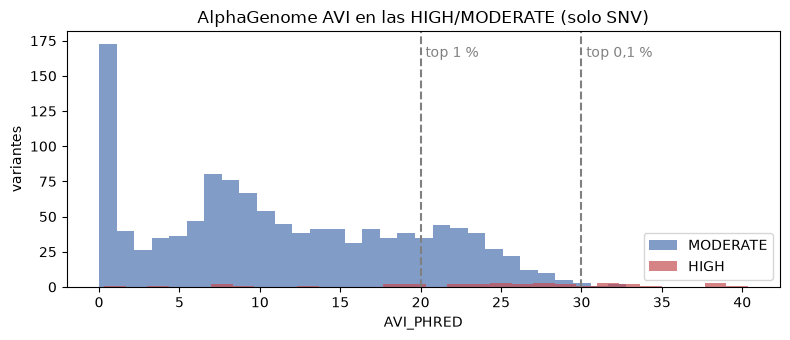

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for imp, color in (("MODERATE", "#4C72B0"), ("HIGH", "#C44E52")):
    ax.hist(scored.loc[scored.impact == imp, "avi_phred"], bins=30, alpha=0.7, label=imp, color=color)
for x, lab in ((20, "top 1 %"), (30, "top 0,1 %")):
    ax.axvline(x, ls="--", color="grey"); ax.text(x + 0.3, ax.get_ylim()[1] * 0.9, lab, color="grey")
ax.set_xlabel("AVI_PHRED"); ax.set_ylabel("variantes"); ax.set_title("AlphaGenome AVI en las HIGH/MODERATE (solo SNV)")
ax.legend(); plt.tight_layout(); plt.show()

Lectura: la modalidad dominante para variantes codificantes es la **conservación** (`CACTUS_241_WAY`) seguida de **AlphaMissense**; splicing y terminación de proteína aparecen en las HIGH. Que AVI y CADD compartan escala Phred permite usarlos juntos en el Paso 5 como evidencia in-silico.

## Chequeo del panel MVA a nivel gen

`docs/00-references.md` §2 define el panel: *BUB1B* (MVA1), *CEP57* (MVA2), *TRIP13* (MVA3), *MAD2L1BP*. Antes de cualquier priorización miramos si alguno tiene variantes raras protein-altering. La tabla muestra **gen, tipo y anotaciones**, sin coordenadas: por regla del repo (`CLAUDE.md`) las coordenadas del paciente no se commitean; están en el VCF gitignoreado.

In [11]:
PANEL = ["BUB1B", "CEP57", "TRIP13", "MAD2L1BP"]
panel_rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3B):
    g = info.get("GENE_SYMBOL")
    if g in PANEL:
        panel_rows.append({
            "gene": g, "consequence": info.get("CONSEQUENCE"), "impact": info.get("PUTATIVE_IMPACT"),
            "zygosity": zygosity(sample), "AB": fnum(info.get("AB_FILTER")),
            "gnomAD_AF": fnum(info.get("GNOMAD_AF")), "CADD": fnum(info.get("CADD_PHRED")), "REVEL": fnum(info.get("REVEL")),
            "AVI_PHRED": fnum(info.get("AVI_PHRED")), "AVI_feature": info.get("REGULATORY_FEATURE"),
            "ClinVar": (info.get("CLINVAR_SIG") or "-").replace("_", " "), "OMIM": info.get("OMIM_PHENOTYPE") or "-",
        })
panel = pd.DataFrame(panel_rows)
for g in PANEL:
    if g not in set(panel.gene):
        print(f"{g}: sin variantes HIGH/MODERATE raras")
panel

CEP57: sin variantes HIGH/MODERATE raras
TRIP13: sin variantes HIGH/MODERATE raras
MAD2L1BP: sin variantes HIGH/MODERATE raras


,gene,consequence,impact,zygosity,AB,gnomAD_AF,CADD,REVEL,AVI_PHRED,AVI_feature,ClinVar,OMIM
0,BUB1B,stop_gained,HIGH,HET,0.543,0.000033,36.0,NaN,33.76,PROTEIN_TERMINATION,Pathogenic|Likely pathogenic,257300
1,BUB1B,missense_variant,MODERATE,HET,0.464,NaN,24.5,0.472,25.61,ALPHAMISSENSE,-,-


Lectura (anotación de investigación, no una afirmación clínica): el único gen del panel con variantes protein-altering raras es ***BUB1B*, con dos variantes heterocigotas**: una stop-gain ya clasificada Patogénica/Probablemente patogénica en ClinVar para MVA1 (OMIM 257300), y una missense ausente de gnomAD con CADD, REVEL y AVI en rango sugestivo. Dos heterocigotas en un gen autosómico recesivo es exactamente el patrón de heterocigosis compuesta descrito para MVA1 en las referencias. La fase (si están en cromosomas distintos) no se puede determinar desde un VCF de una sola muestra.

## Qué sigue

* **Paso 4** (`track1_step4_prioritize.py`): similitud semántica HPO por gen + evidencia bialélica + chequeo del panel. Ya está implementado y testeado; **no se ha corrido sobre los datos reales** por decisión del equipo.
* **Paso 5** (`track1_step5_submission.py`): score `epcr` y CSV de submission con separación forzada entre filas (F-max penaliza empates). Incluye el filtro gnomAD AF ≤ 1 %.
* Pendiente de discusión: reemplazar dbSNP Common por gnomAD en el Paso 2.

### Figura: las dos variantes de *BUB1B* explicadas para no especialistas · Figure: the two *BUB1B* variants explained for non-specialists

Versión interactiva con selector Español/English arriba a la derecha · Interactive version with an Español/English switch at the top right: [`docs/figures/bub1b_variantes_explicado.html`](../../docs/figures/bub1b_variantes_explicado.html) (regenerar con · regenerate with `python docs/figures/build_bub1b_figure.py`).

**🇪🇸** Mapa del gen (cromosoma 15 → 23 exones → cambios en los exones 17 y 23), zoom a las letras con sus vecinas del genoma de referencia, y explicación de la heterocigosis con los dos escenarios de fase posibles. El cambio 1 convierte el trío TTA (leucina) en TGA, una señal de STOP: la proteína se corta en el ladrillo 751 de 1064. El cambio 2 convierte AAT (asparagina) en AAG (lisina): la proteína se completa con otra pieza. Cada cambio aparece en la mitad de las lecturas, por eso está en una sola de las dos copias del gen (heterocigoto); con el ADN de una sola persona no se puede saber si están en copias distintas (heterocigosis compuesta, el patrón de MVA tipo 1) o en la misma.

**🇬🇧** Gene map (chromosome 15 → 23 exons → changes in exons 17 and 23), letter-level zoom with reference-genome neighbours, and an explanation of heterozygosity with the two possible phase scenarios. Change 1 turns the TTA triplet (leucine) into TGA, a STOP signal: the protein is cut short at brick 751 of 1064. Change 2 turns AAT (asparagine) into AAG (lysine): the protein is completed with a different piece. Each change shows up in half of the reads, so it sits on only one of the two gene copies (heterozygous); with one person's DNA alone we cannot tell whether they are on different copies (compound heterozygosity, the MVA type 1 pattern) or on the same one.

![The two BUB1B variants, explained](../../docs/figures/bub1b_variants_explained_en.png)